# Flow Matching for Generating a Checkerboard Distribution

This interactive tutorial demonstrates how to use a flow matching model to transform samples from a simple Gaussian distribution to a complex target distribution — in this case, a checkerboard pattern. We implement and train a flow-based neural network and visualize the learned transformation.

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch import Tensor
from matplotlib import pyplot as plt

## Define the Flow Matching Model

In [2]:
class Flow(nn.Module): 
    def __init__(self, dim: int = 2, h: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim + 1, h),
            nn.ELU(),
            nn.Linear(h, h),
            nn.ELU(),
            nn.Linear(h, h),
            nn.ELU(),
            nn.Linear(h, dim)
        )

    def forward(self, t: Tensor, xt: Tensor) -> Tensor:
        combined_input = torch.cat((t, xt), -1)
        return self.net(combined_input)

    def step(self, xt: Tensor, t_start: Tensor, t_end: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(xt.shape[0], 1)
        midpoint_time = t_start + (t_end - t_start) / 2
        intermediate_value = self(xt=xt, t=t_start)
        updated_xt = xt + intermediate_value * (t_end - t_start) / 2
        midpoint_output = self(t=midpoint_time, xt=updated_xt)
        return xt + (t_end - t_start) * midpoint_output


## Sample from Initial and Target Distributions

In [3]:
def sample_from():
    rv1 = torch.rand(10000) * 4 - 2
    rv2 = torch.rand(10000) * 4 - 2
    mask = (torch.floor(rv1) + torch.floor(rv2)) % 2 == 0
    x1 = torch.stack((rv1[mask], rv2[mask]), dim=1)
    x0 = torch.randn_like(x1)
    return x0, x1

## Train the Flow Matching Model

In [4]:
def train(flow, optimizer, loss_fn, epochs=10000):
    for _ in range(epochs):
        x0, x1 = sample_from()
        t = torch.rand(len(x1), 1)
        xt = (1 - t) * x0 + t * x1
        loss = loss_fn(flow(t=t, xt=xt), x1 - x0)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print(f"Loss: {loss.item()}")


### Initialize Model and Start Training

In [8]:
flow = Flow()
optimizer = torch.optim.Adam(flow.parameters(), 1e-3)
loss_fn = nn.MSELoss()
train(flow, optimizer, loss_fn)


Loss: 1.712213158607483


## Visualize the Transformation from Gaussian to Checkerboard

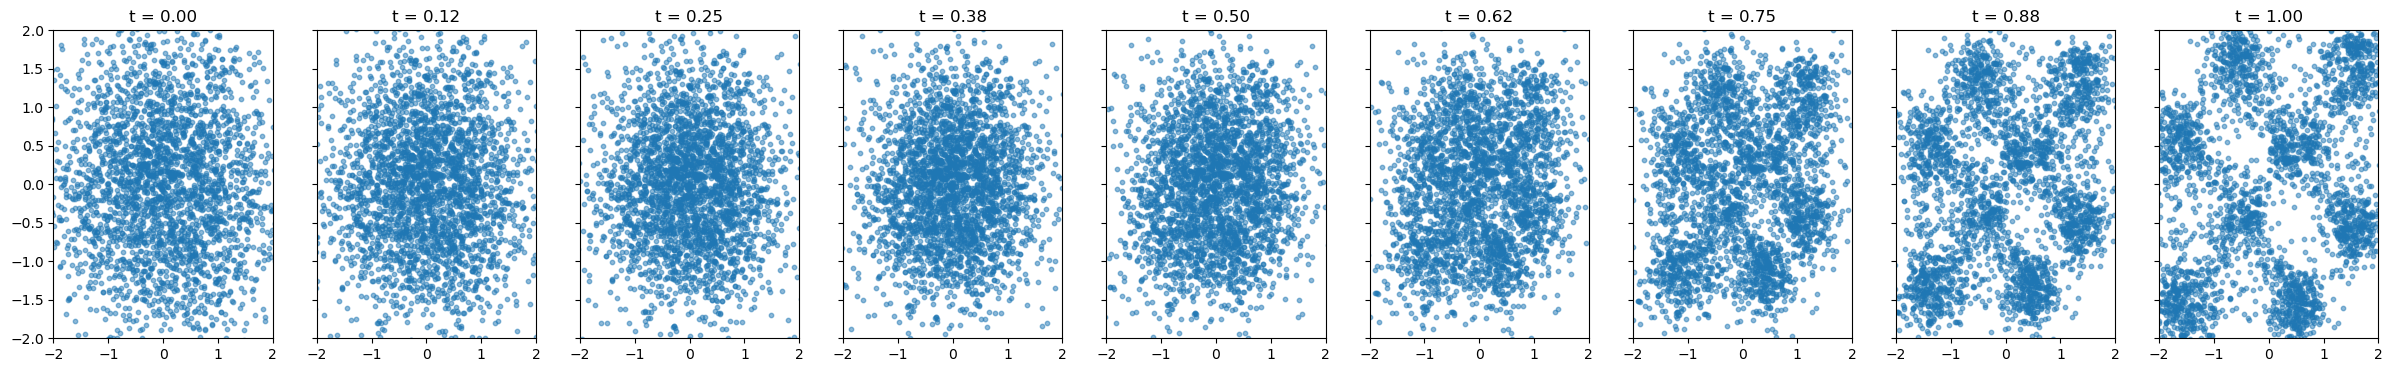

In [6]:
x = torch.randn(3000, 2)
n_steps = 8
fig, axes = plt.subplots(1, n_steps + 1, figsize=(30, 4), sharex=True, sharey=True)
time_steps = torch.linspace(0, 1.0, n_steps + 1)
axes[0].scatter(x.detach()[:, 0], x.detach()[:, 1], s=10, alpha=0.50)
axes[0].set_title(f't = {time_steps[0]:.2f}')
axes[0].set_xlim(-2.0, 2.0)
axes[0].set_ylim(-2.0, 2.0)
for i in range(n_steps):
    x = flow.step(xt=x, t_start=time_steps[i], t_end=time_steps[i + 1])
    axes[i + 1].scatter(x.detach()[:, 0], x.detach()[:, 1], s=10, alpha=0.50)
    axes[i + 1].set_title(f't = {time_steps[i + 1]:.2f}')
plt.show()


## Plot the Ground Truth Checkerboard Distribution

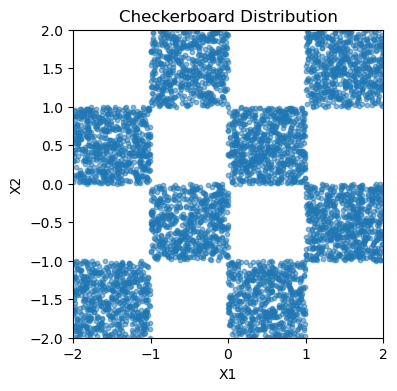

In [7]:
rv1 = torch.rand(10000) * 4 - 2
rv2 = torch.rand(10000) * 4 - 2
mask = (torch.floor(rv1) + torch.floor(rv2)) % 2 == 0
x1 = torch.stack((rv1[mask], rv2[mask]), dim=1)
x1_np = x1.numpy()
plt.figure(figsize=(4, 4))
plt.scatter(x1_np[:, 0], x1_np[:, 1], s=10, alpha=0.50)
plt.title("Checkerboard Distribution")
plt.xlabel("X1")
plt.ylabel("X2")
plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.show()
